In [39]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error as mse, mean_absolute_error as mae, r2_score as r2

In [40]:
def get_score(actual, predicted):
    return {
        "MSE": mse(actual, predicted),
        "MAE": mae(actual, predicted),
        "R2": r2(actual, predicted)
    }


## 1. Load and Explore the Dataset

In [42]:
df = pd.read_csv("housing.csv")
df = df.drop(columns=["latitude"])
print("Dataset size:", df.shape)

Dataset size: (20640, 9)


In [43]:
df.head()

,longitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


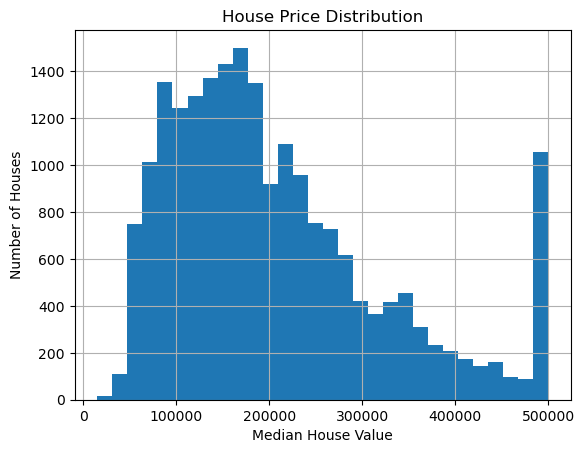

In [44]:
df['median_house_value'].hist(bins=30)
plt.xlabel("Median House Value")
plt.ylabel("Number of Houses")
plt.title("House Price Distribution")
plt.show()

## Finding Correlation

In [45]:
# Find correlation with house price
corr = df.corr(numeric_only=True)['median_house_value'].drop('median_house_value')

# Display correlations
print(corr.sort_values(ascending=False))

# Select two features with highest correlation
features = corr.abs().sort_values(ascending=False).head(2).index

X = df[features]
y = df['median_house_value']

print("Selected Features:", list(features))

median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
Name: median_house_value, dtype: float64
Selected Features: ['median_income', 'total_rooms']


## 2. Split the Data

In [46]:
model = LinearRegression()
best_error = float("inf")

for i in range(1, 11):
    if i == 10:
        break  # Leave some data for testing

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=i / 10, random_state=42
    )
    model.fit(X_train, y_train)
    model_pred = model.predict(X_test)
    error = mse(y_test, model_pred)

    if error < best_error:
        best_error = error
        best_split = i / 10


print("Best split:", round(best_split * 100), "% train,",round((1 - best_split) * 100), "% test")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=best_split, random_state=42
)


Best split: 70 % train, 30 % test


## 3. Linear Regression

In [47]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print("Linear Regression:", get_score(y_test, linear_pred))


Linear Regression: {'MSE': 6916933314.097756, 'MAE': 62309.47127273078, 'R2': 0.4729276314743973}


## 4. Polynomial Regression

In [48]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
poly_pred = poly_model.predict(X_test_poly)

print("Polynomial Regression:", get_score(y_test, poly_pred))


Polynomial Regression: {'MSE': 6838944738.607851, 'MAE': 62115.655254091034, 'R2': 0.4788703840404258}


## 5. Compare Both Models

In [49]:
comparison = pd.DataFrame({
    "Linear": get_score(y_test, linear_pred),
    "Polynomial": get_score(y_test, poly_pred)
})
comparison.round(3)


,Linear,Polynomial
MSE,6.916933e+09,6.838945e+09
MAE,6.230947e+04,6.211565e+04
R2,4.730000e-01,4.790000e-01


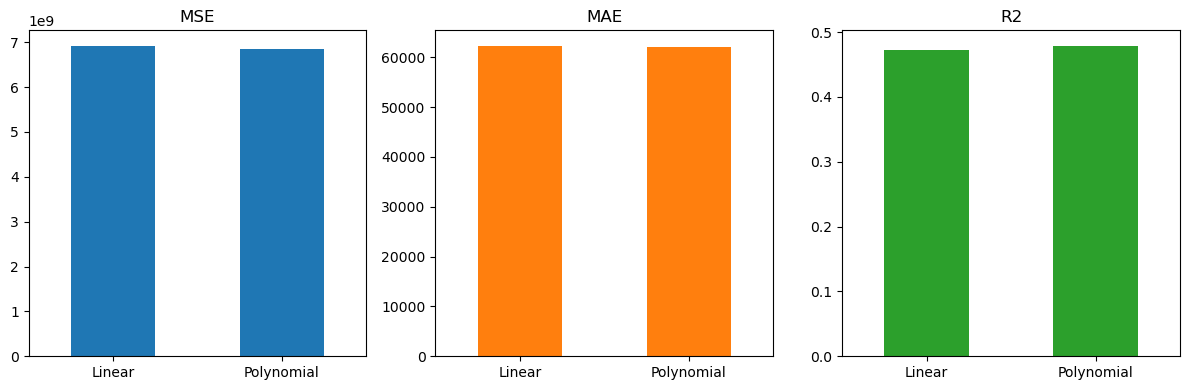

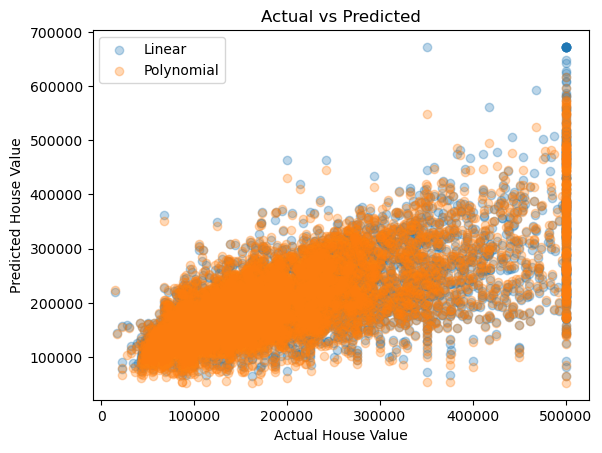

In [50]:
# Bar charts for MSE, MAE and R2
comparison.T.plot.bar(subplots=True, layout=(1, 3), figsize=(12, 4),
                      legend=False, rot=0)
plt.tight_layout()
plt.show()

# Actual vs Predicted values
plt.scatter(y_test, linear_pred, alpha=0.3, label="Linear")
plt.scatter(y_test, poly_pred, alpha=0.3, label="Polynomial")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()


## 6. Predict a House Price

In [52]:
values = []

for feature in features:
    value = float(input("Enter " + feature + ": "))
    values.append(value)

new_house = pd.DataFrame([values], columns=features)

print("Linear Prediction:", linear_model.predict(new_house)[0])
print("Polynomial Prediction:", poly_model.predict(poly.transform(new_house))[0])

Enter median_income:  50000
Enter total_rooms:  5


Linear Prediction: 2091078083.371954
Polynomial Prediction: 2761277349262.712
